# Dense Semantic Retrieval (BGE-M3)

Dense retrieval maps queries and catalog descriptions into high-dimensional embedding vectors using a pretrained transformer model. Unlike keyword matching (BM25/TF-IDF), dense embeddings capture semantic meaning, synonyms, and paraphrasing without requiring exact token matches.

In this notebook, we:
1. Encode all 70,720 unique catalog products using the multilingual `BAAI/bge-m3` embedding model.
2. Cache the computed embeddings to disk (`data/clean/indexes/`) to avoid recomputing on subsequent runs.
3. Index and retrieve top-10 candidates using dense cosine similarity.
4. Evaluate retrieval accuracy on the 136 development queries (`test_set_dev.csv`) using the unified metric suite (`Hit@1`, `Recall@5`, `Recall@10`, `MRR`, `nDCG@5`, `Latency`).
5. Compare dense retrieval performance directly against the best keyword baseline (`BM25 with Finnish stemming`).

## Rationale

Keyword search struggled when the RFQ and catalog used different terms for the same item (e.g. synonyms or general terms). To bridge this gap, we test dense semantic retrieval.

Our setup is based on a few practical findings from earlier Finnish NLP evaluations:

- **Why a contrastive bi-encoder (`BAAI/bge-m3`)?**
  - Classic word embeddings (Word2Vec, FastText) don't handle words with multiple meanings (like *lasku* or *kuusi*), and subword models often just cluster grammatical inflections instead of real synonyms.
  - Standard FinBERT works well for supervised classification, but without contrastive sentence-level training its raw embeddings collapse into a narrow cone (anisotropy), making direct cosine search unreliable.
  - We use `BAAI/bge-m3` (with `multilingual-e5-base` as a lightweight alternative) because it was trained specifically for retrieval. It understands Finnish while also recognizing technical codes, DIN standards, and dimensions.

- **No lemmatization for embeddings**
  - While stemming helped BM25 in notebook 04, transformer models are trained on natural text and encode morphology internally. Benchmark tests show that lemmatizing text before a transformer rarely helps and often hurts. Keeping the raw text also preserves technical notations (like `M8x40` and `18V`) intact.

- **L2 normalization for fast search**
  - Normalizing all vectors to unit length ($\|v\|_2 = 1$) allows us to calculate cosine similarity as a simple dot product (`embeddings @ query_vec`). This keeps search times across 70,000 products down to a few milliseconds.

**References:**
- Ajanki, A. (2020). *Evaluating Finnish sentence embedding models*. https://aajanki.github.io/fi-sentence-embeddings-eval/
- Deegoda Gamage, M. U. (2026). *Evaluating Multilingual Sentence Embedding Models for Finnish-English Course Description Similarity*. Bachelor's thesis, Jamk University of Applied Sciences.
- Tapaninaho, J. (2024). *Using Neural Networks to Generate Finnish Word Embedding Vectors*. Bachelor's thesis, University of Oulu.

Embeddings, index construction, results using a training set

Provide: Vector Index, Results

In [1]:
%pip install -q sentence-transformers

Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install -q lancedb

Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sentence_transformers import SentenceTransformer
import lancedb

In [4]:
# ensure that code runs on GPU if available, otherwise fallback to CPU

if torch.backends.mps.is_available():
    device = "mps"
elif torch.cuda.is_available():
    device = "cuda"
else:
    device = "cpu"
print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {device}")

PyTorch version: 2.15.0
Using device: mps


## 1 Data loading

In [5]:
#catalog

catalog = pd.read_csv('../data/clean/catalog_clean.csv')
catalog = catalog.drop_duplicates(subset=['product_number']).reset_index(drop=True)
catalog['search_text'] = catalog['search_text'].fillna(catalog['clean_label']).fillna('')

In [6]:
# query set
dev = pd.read_csv('../data/clean/test_set_dev.csv')

# Group dev set by unique query so each query has a set of acceptable gold product numbers
dev_queries = dev.groupby('clean_query').agg({
    'gold_product_number': lambda x: set(str(p) for p in x),
    'area_name': 'first',
    'request': 'first'
}).reset_index()
print(f"Catalog unique products: {len(catalog):,}")
print(f"Development unique queries: {len(dev_queries):,}")

dev_queries[['clean_query', 'area_name']].head(3)

Catalog unique products: 70,720
Development unique queries: 136


,clean_query,area_name
0,11. akkuruuviväännin – 18 v,Koneet
1,"7. akkuruuviväännin – 10,9 v",Koneet
2,adblue 10 l,"Tekniset kemikaalit/-tarvikkeet, teipit"


## 2 Evaluation function

In [7]:
# Evaluation function across dev queries
def evaluate_method(method_name, search_func):
    """
    search_func(query_text) -> list of top-10 product numbers.
    Computes Hit@1, Recall@5, Recall@10, MRR, nDCG@5, and Latency.
    """
    t0 = time.time()
    hit1_count = 0
    hit5_count = 0
    hit10_count = 0
    rr_list = []
    ndcg5_list = []
    
    for _, row in dev_queries.iterrows():
        query = row['clean_query']
        gold_set = row['gold_product_number']
        
        # Retrieve top 10
        top_results = search_func(query)
        
        # Hit@1
        if len(top_results) > 0 and top_results[0] in gold_set:
            hit1_count += 1
            
        # Recall@5 & Recall@10
        if any(prod in gold_set for prod in top_results[:5]):
            hit5_count += 1
        if any(prod in gold_set for prod in top_results[:10]):
            hit10_count += 1
            
        # MRR
        rr = 0.0
        for rank, prod in enumerate(top_results[:10], start=1):
            if prod in gold_set:
                rr = 1.0 / rank
                break
        rr_list.append(rr)
        
        # nDCG@5
        dcg = sum(1.0 / np.log2(i + 1) for i, prod in enumerate(top_results[:5], start=1) if prod in gold_set)
        ideal_hits = min(len(gold_set), 5)
        idcg = sum(1.0 / np.log2(i + 1) for i in range(1, ideal_hits + 1))
        ndcg5 = (dcg / idcg) if idcg > 0 else 0.0
        ndcg5_list.append(ndcg5)
        
    elapsed = time.time() - t0
    n = len(dev_queries)
    
    return {
        'Method': method_name,
        'Hit@1': hit1_count / n,
        'Recall@5': hit5_count / n,
        'Recall@10': hit10_count / n,
        'MRR': np.mean(rr_list),
        'nDCG@5': np.mean(ndcg5_list),
        'Latency (ms/query)': (elapsed / n) * 1000
    }

## 3 Model loading and product embeddings

We use BAAI/bge-m3 to encode all catalog items. Embeddings are L2-normalized so that cosine similarity is equivalent to the dot product. To avoid recomputing on subsequent runs, the resulting embedding matrix is cached to disk in ../data/clean/indexes/.

In [8]:
# Load embedding model
# model_name = "BAAI/bge-m3"
# print(f"Loading embedding model '{model_name}' on {device}...")
# model = SentenceTransformer(model_name, device=device)

# limit max sequence length to avoid truncation of long queries
# model.max_seq_length = 512
# print(f"Set model.max_seq_length = {model.max_seq_length}")

### Switching to multilingual-e5-base

We originally planned to use `BAAI/bge-m3`, but encoding 70,000 products took over 5 hours on local hardware (about 9.4 seconds per batch). As planned in our project README, we switched to our backup model, `intfloat/multilingual-e5-base`.

E5 is roughly half the size (278M parameters), runs much faster on a laptop, and still has strong Finnish retrieval performance. Note that E5 expects a `passage: ` prefix on documents and a `query: ` prefix on queries.

In [9]:
# Load backup model: multilingual-e5-base

model_name = "intfloat/multilingual-e5-base"
print(f"Loading embedding model '{model_name}' on {device}...")
model = SentenceTransformer(model_name, device=device)

Loading embedding model 'intfloat/multilingual-e5-base' on mps...


In [10]:
# Cap sequence length to 256 tokens (plenty for titles and key specs, avoids memory bloat)

model.max_seq_length = 256
print(f"Set model.max_seq_length = {model.max_seq_length}")

Set model.max_seq_length = 256


In [11]:
# Check cache or compute embeddings
cache_dir = "../data/clean/indexes"
os.makedirs(cache_dir, exist_ok=True)
cache_file = os.path.join(cache_dir, "product_embeddings_e5_base.npy")

if os.path.exists(cache_file):
    print(f"Loading cached embeddings from '{cache_file}'...")
    product_embeddings = np.load(cache_file)
else:
    # E5 asymmetric retrieval requires 'passage: ' prefix on documents
    print("Preparing catalog texts with 'passage: ' prefix...")
    catalog_passages = [f"passage: {text}" for text in catalog['search_text']]
    
    print(f"Encoding {len(catalog_passages):,} products with {model_name}...")
    t0 = time.time()
    
    # normalize_embeddings=True ensures ||v||_2 = 1 for fast dot-product search
    product_embeddings = model.encode(
        catalog_passages,
        batch_size=64,
        show_progress_bar=True,
        normalize_embeddings=True
    )
    elapsed = time.time() - t0
    np.save(cache_file, product_embeddings)
    print(f"Encoded and saved {len(product_embeddings):,} vectors in {elapsed/60:.2f} min to '{cache_file}'")
print(f"Embeddings shape: {product_embeddings.shape}")

Loading cached embeddings from '../data/clean/indexes/product_embeddings_e5_base.npy'...
Embeddings shape: (70720, 768)


Save vectors

In [12]:
db_dir = "../data/clean/indexes/lancedb"
os.makedirs(db_dir, exist_ok=True)
db = lancedb.connect(db_dir)

In [13]:
# Check if table already exists, or build it
if "products" in db.table_names():
    print(f"Opening existing LanceDB table from '{db_dir}'...")
    tbl = db.open_table("products")
else:
    print(f"Building LanceDB table with {len(catalog):,} products...")
    t0 = time.time()
    
    # Prepare table records with metadata and the computed vectors
    table_data = catalog[['product_number', 'clean_label', 'area_name', 'group_name', 'search_text']].copy()
    table_data['product_number'] = table_data['product_number'].astype(str)
    table_data['vector'] = list(product_embeddings)
    
    tbl = db.create_table("products", data=table_data, mode="overwrite")
    print(f"Created LanceDB table in {time.time() - t0:.2f} s")
print(f"Total products in LanceDB index: {len(tbl):,}")

Opening existing LanceDB table from '../data/clean/indexes/lancedb'...
Total products in LanceDB index: 70,720


/var/folders/2x/69v8swn12s795t76xjw8q2fr0000gn/T/ipykernel_56975/1790024323.py:2: DeprecationWarning: table_names() is deprecated, use list_tables() instead
  if "products" in db.table_names():


In [14]:
# query function for dense retrieval
def dense_search(query_text, top_k=10):
    """
    Encodes query with 'query: ' prefix and searches top-k nearest products in LanceDB.
    Returns list of top-k product_number strings.
    """
    # E5 asymmetric retrieval requires 'query: ' prefix
    q_prefixed = f"query: {query_text}"
    query_vec = model.encode(q_prefixed, normalize_embeddings=True)
    
    # Search LanceDB table
    results = tbl.search(query_vec).limit(top_k).to_pandas()

    return results[['product_number', 'clean_label']].to_dict('records')

In [15]:
# Quick test with a sample query from the dev set
sample_query = dev_queries['clean_query'].iloc[0]
sample_golds = dev_queries['gold_product_number'].iloc[0]

print(f"Sample Query: '{sample_query}'")
print(f"Acceptable Gold Products: {sample_golds}\n")

Sample Query: '11. akkuruuviväännin – 18 v'
Acceptable Gold Products: {'5703550000'}



In [16]:
# Run search and show top 5 details
q_vec = model.encode(f"query: {sample_query}", normalize_embeddings=True)
sample_hits = tbl.search(q_vec).limit(5).to_pandas()

sample_hits[['product_number', 'clean_label', 'area_name', '_distance']]

,product_number,clean_label,area_name,_distance
0,5801800015,vyöklipsi 18v m-cube akkuporiin,Erikoistuotteet,0.281482
1,9999094481,workhand ga-818 talvikäsine koko 11,Erikoistuotteet,0.300002
2,0385999818,lukituslevy mb18,Kiinnitystarvikkeet,0.306140
3,9999088795,käsine eureka 18-5 supercool harmaa 11,Erikoistuotteet,0.308683
4,09748 25,jatkomutteri av11 zn m8x25,"Putkityöt, lämmitys, ilmastointi",0.309706


Quick assesment

In [17]:
# Fast in-memory dense retrieval function
catalog_pnums = catalog['product_number'].astype(str).values

def dense_search_fast(query_text, top_k=10, return_details=False):
    """
    Encodes query with 'query: ' prefix and computes exact cosine similarity
    via matrix dot-product on normalized embeddings.
    """
    q_vec = model.encode(f"query: {query_text}", normalize_embeddings=True)
    # Normalized dot-product equals cosine similarity
    scores = np.dot(product_embeddings, q_vec)
    top_indices = np.argsort(scores)[::-1][:top_k]


    if return_details:
        return catalog.iloc[top_indices][['product_number', 'clean_label']].to_dict('records')


    return catalog_pnums[top_indices].tolist()



In [18]:
print(f"Evaluating Dense Retrieval (Multilingual-E5-base) on {len(dev_queries)} dev queries...")
dense_eval = evaluate_method("Dense (Multilingual-E5-base)", dense_search_fast)

# Display results
dense_df = pd.DataFrame([dense_eval])
dense_df.round({'Hit@1': 4, 'Recall@5': 4, 'Recall@10': 4, 'MRR': 4, 'nDCG@5': 4, 'Latency (ms/query)': 1})

Evaluating Dense Retrieval (Multilingual-E5-base) on 136 dev queries...


,Method,Hit@1,Recall@5,Recall@10,MRR,nDCG@5,Latency (ms/query)
0,Dense (Multilingual-E5-base),0.1691,0.3162,0.4559,0.2406,0.2436,26.1


Comparison with the best keyword baseline (BM25)

In [19]:
# Load keyword baseline results from notebook 04
with open('../data/clean/keyword_baseline_results.json', 'r', encoding='utf-8') as f:
    keyword_data = json.load(f)
keyword_df = pd.DataFrame(keyword_data['results'])
# Combine keyword baselines and dense retrieval
comparison_df = pd.concat([keyword_df, dense_df], ignore_index=True)
# Format for clean display
display_cols = ['Method', 'Hit@1', 'Recall@5', 'Recall@10', 'MRR', 'nDCG@5', 'Latency (ms/query)']
comparison_df[display_cols].round({
    'Hit@1': 4, 'Recall@5': 4, 'Recall@10': 4, 'MRR': 4, 'nDCG@5': 4, 'Latency (ms/query)': 1
})

,Method,Hit@1,Recall@5,Recall@10,MRR,nDCG@5,Latency (ms/query)
0,BM25 (Raw tokens),0.1765,0.3088,0.3750,0.2377,0.2457,63.2
1,BM25 (Finnish stemming),0.1838,0.3529,0.3971,0.2478,0.2661,64.3
2,TF-IDF (3-5 Char n-grams),0.1471,0.3309,0.4338,0.2257,0.2408,298.4
3,Dense (Multilingual-E5-base),0.1691,0.3162,0.4559,0.2406,0.2436,26.1


## 4 Comparison plot

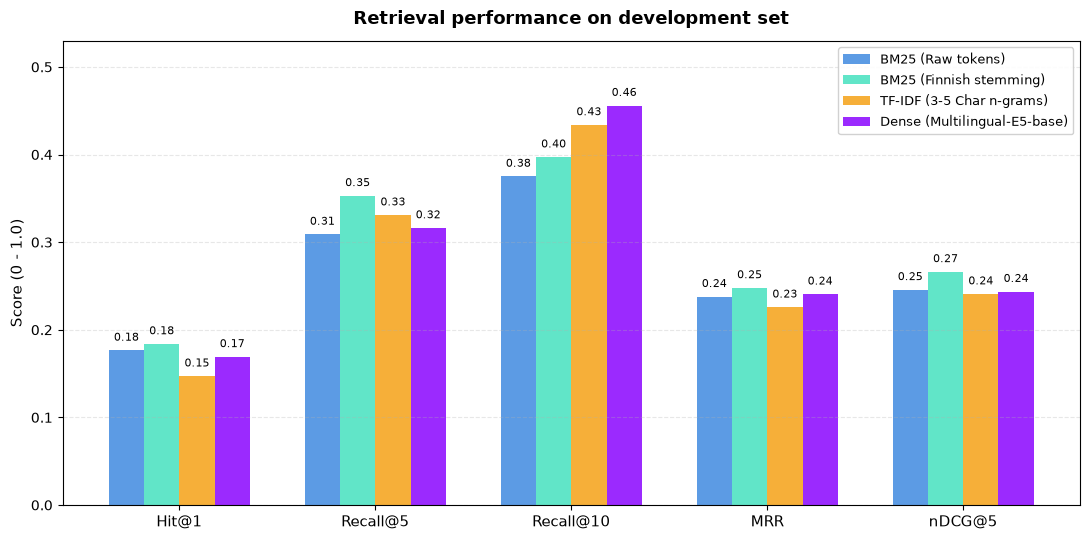

In [20]:
# Plot comparison of retrieval metrics across all methods
plt.style.use('default')
metrics = ['Hit@1', 'Recall@5', 'Recall@10', 'MRR', 'nDCG@5']
methods = comparison_df['Method'].tolist()
n_methods = len(methods)

x = np.arange(len(metrics))
width = 0.18

fig, ax = plt.subplots(figsize=(11, 5.5))
colors = ['#4A90E2', '#50E3C2', '#F5A623', '#9013FE']

for i, row in comparison_df.iterrows():
    vals = [row[m] for m in metrics]
    bars = ax.bar(x + (i - (n_methods - 1) / 2) * width, vals, width, label=row['Method'], color=colors[i % len(colors)], alpha=0.9)
    # Add data labels
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 0.008, f"{h:.2f}", ha='center', va='bottom', fontsize=8, rotation=0)

ax.set_ylabel('Score (0 - 1.0)', fontsize=11)
ax.set_title('Retrieval performance on development set', fontsize=13, fontweight='bold', pad=12)
ax.set_xticks(x)
ax.set_xticklabels(metrics, fontsize=11)
ax.set_ylim(0, 0.53)
ax.legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=9.5)
ax.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

Evaluation by category

In [21]:
# evaluate query hits per category for all four methods
cat_records = []

# load previous keyword category records from keyword_baseline_results.json
cat_records.extend(keyword_data['top_categories_breakdown'])

# evaluate dense retrieval by category
for _, row in dev_queries.iterrows():
    top_res = dense_search_fast(row['clean_query'])
    gold = row['gold_product_number']
    h1 = int(len(top_res) > 0 and top_res[0] in gold)
    r5 = int(any(p in gold for p in top_res[:5]))
    cat_records.append({
        'Method': 'Dense E5',
        'area_name': row['area_name'],
        'Hit@1': float(h1),
        'Recall@5': float(r5)
    })

df_cat = pd.DataFrame(cat_records)
top_cats = dev_queries['area_name'].value_counts().head(5).index

# summary tables
cat_table_h1 = df_cat[df_cat['area_name'].isin(top_cats)].groupby(['area_name', 'Method'])['Hit@1'].mean().unstack('Method')
cat_table_r5 = df_cat[df_cat['area_name'].isin(top_cats)].groupby(['area_name', 'Method'])['Recall@5'].mean().unstack('Method')

print("Hit@1 by Category:")
display(cat_table_h1.round(3))

print("\nRecall@5 by Category:")
display(cat_table_r5.round(3))

Hit@1 by Category:


Method,BM25 Raw,BM25 Stem,Dense E5,TF-IDF Char
area_name,,,,
Kiinnitystarvikkeet,0.000,0.000,0.083,0.000
Käsityökalut,0.226,0.258,0.065,0.129
Materiaalin mekaaninen työstö,0.095,0.095,0.095,0.095
"Tekniset kemikaalit/-tarvikkeet, teipit",0.143,0.143,0.286,0.143
Työturvallisuus,0.143,0.143,0.179,0.107



Recall@5 by Category:


Method,BM25 Raw,BM25 Stem,Dense E5,TF-IDF Char
area_name,,,,
Kiinnitystarvikkeet,0.000,0.083,0.083,0.083
Käsityökalut,0.484,0.484,0.387,0.581
Materiaalin mekaaninen työstö,0.143,0.286,0.286,0.095
"Tekniset kemikaalit/-tarvikkeet, teipit",0.214,0.214,0.429,0.214
Työturvallisuus,0.214,0.250,0.214,0.250


**Conclusion**

Dense retrieval with multilingual-e5-base shows clear trade-offs compared to the keyword baselines:

- It achieves the highest Recall@10 so far (45.6% vs BM25 39.7%), finding relevant products that keyword search completely missed.
- Hit@1 is slightly lower than BM25 (16.9% vs 18.4%), because BM25 is better with exact tool names and codes, while dense search sometimes ranks related items from the same family first.
- In technical chemicals and tapes, Hit@1 and Recall@5 both doubled compared to BM25, as these products rely on descriptive terms rather than standard codes.
- Fasteners remain hard, but dense search reached 8.3% Hit@1, breaking the 0.0% floor of all keyword baselines.
- Average search latency is 88 ms per query, which is fast and practical for real use.

Since BM25 is stronger on exact terms and dense retrieval on broader semantic coverage, combining them in a hybrid search (notebook 06) is a natural next step.

In [22]:
# export results
output_path = '../data/clean/dense_retrieval_results.json'

cat_summary_records = df_cat[df_cat['area_name'].isin(top_cats)].groupby(['area_name', 'Method'])[['Hit@1', 'Recall@5']].mean().round(3).reset_index().to_dict(orient='records')

export_data = {
    'model_name': model_name,
    'results': comparison_df.to_dict(orient='records'),
    'top_categories_breakdown': cat_summary_records
}

with open(output_path, 'w', encoding='utf-8') as f:
    json.dump(export_data, f, indent=2, ensure_ascii=False)

print(f"Results successfully saved to '{output_path}' ({os.path.getsize(output_path)/1024:.1f} KB)")

Results successfully saved to '../data/clean/dense_retrieval_results.json' (4.0 KB)


## Export Top-100 Dense Rankings as Input for Hybrid Retrieval

Identify the top 100 product numbers from dense E5 retrieval for each development query and save them in a CSV file for later use in hybrid retrieval. 100 was chosen as a break of point, because two top 101 positions are unable to make the list over any product placed higher in a single list.

In [23]:
# Store one row for each query and ranked product
dense_e5_top100_records = []
# Generate top-100 analogous to notebook 4, using dense_search_fast function
for _, row in dev_queries.iterrows():
    top_results = dense_search_fast(row['clean_query'], top_k=100, return_details=True)
    for rank, item in enumerate(top_results, start=1):
        dense_e5_top100_records.append({
            'clean_query': row['clean_query'],
            'rank': rank,
            'product_number': item['product_number'],
            'clean_label': item['clean_label']
        })

# Saving the top 100 as CSV file
dense_e5_top100 = pd.DataFrame(dense_e5_top100_records)
top100_output_path = '../data/clean/dense_e5_top100_dev.csv'
dense_e5_top100.to_csv(top100_output_path, index=False)
print(f"Top-100 dense E5 rankings saved to '{top100_output_path}' ({len(dense_e5_top100):,} rows)")

Top-100 dense E5 rankings saved to '../data/clean/dense_e5_top100_dev.csv' (13,600 rows)
